In [1]:
using Pkg 

Pkg.activate("..")

using MiCRM_stability
using LinearAlgebra, KrylovKit
using StatsBase
using Distributions
using JLD2
using Random

using CairoMakie

using Graphs
using GraphMakie
using NetworkLayout

  Activating project at `~/Projects/Working/HIFMB/MiCRM_stability`


In [2]:
#plotting constants
inch = 96
pt = 4/3
cm = inch / 2.54

37.79527559055118

In [3]:
#get parameter names
fe = fieldnames(MiCRM_stability.exponential_params)
fs = fieldnames(MiCRM_stability.structural_params)
fs = filter(x -> x ∉ [:χ,:D, :ϕ_norm_inv,:γ, :η], fs)
    
names_ =  vcat(fe...,fs..., "Cu", "Cd")

# #latex names
fe_L = [L"g^{(x)}",L"g^{(s)}",L"m^{(x)}",L"f^{(y)}",L"\lambda^{(g)}",L"i^{(y)}",L"o^{(y)}"]
fs_L = [L"\alpha",L"\beta",L"\Lambda^*",L"\Omega^*",L"\rho",L"\tilde{\rho}",L"\sigma",L"\tilde{\sigma}",L"C_U", L"C_D"]

# # #concatanate
names_ = string.(names_)
names_L = vcat(fe_L,fs_L)

# # #load
res = load("../Results/data/dynamic_stabiltiy.jld2")

Dict{String, Any} with 3 entries:
  "v" => Vector{Any}[[0.00163815+0.0im, 0.92493+0.0im, 0.00182397+0.0im, 0.0085…
  "l" => Complex[-0.217522+0.0im, 0.0415239+0.0im, 0.0964716+0.0im, 0.00105919+…
  "p" => Any[[0.222959, 0.777384, 0.847295, 1.00571, 0.406672, 0.354132, 0.9270…

In [4]:
stab = (real(res["l"]) .< 0) 
println("overall stable: ", mean(stab))
stab |> sum

overall stable: 0.6477


6477

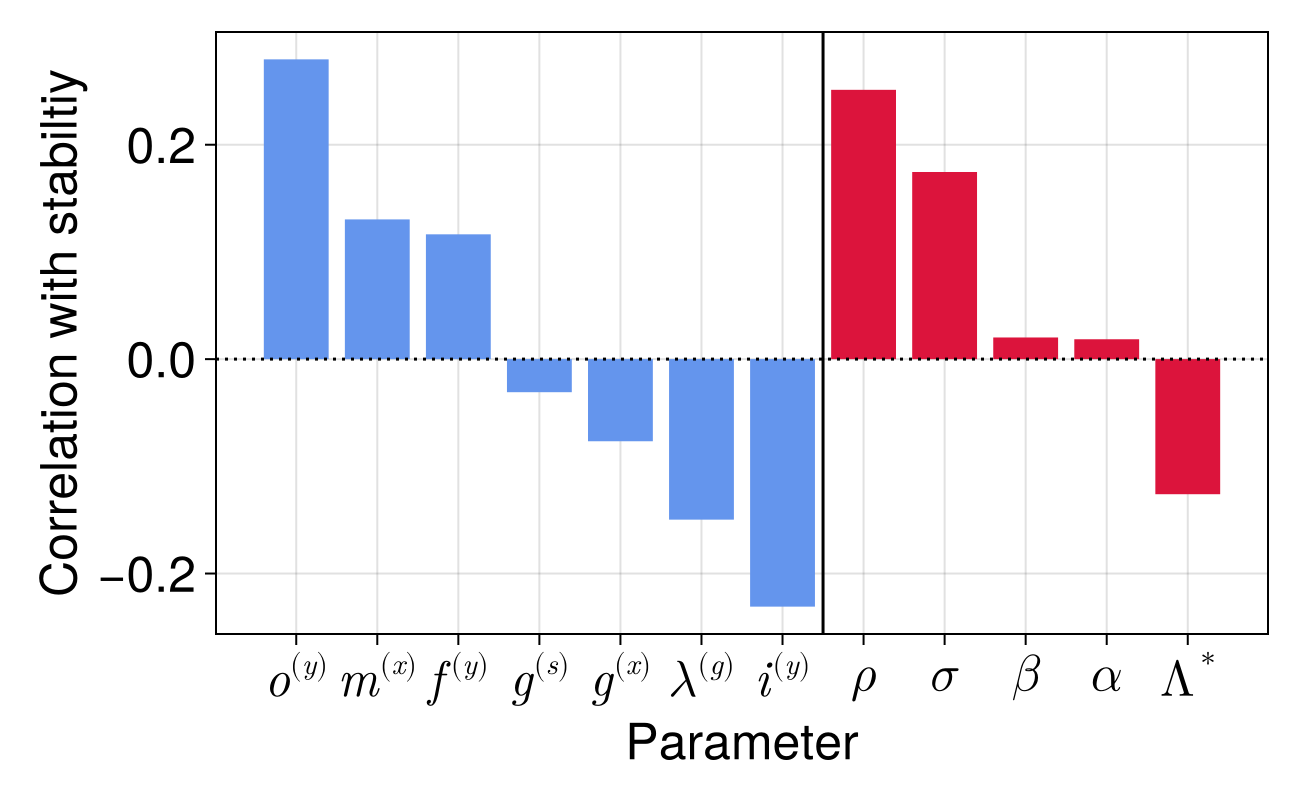

In [5]:
# #filter parameters
p_ind = collect(eachindex(names_))
rm_ind = findall(names_ .∈ Ref(["γ","η","χ","ϕ","σ̃","ρ̃","Ω","Cu","Cd"]))
p_ind = filter(x -> x .∉ Ref(rm_ind), p_ind)

#filter name vectors
names_1 = names_[p_ind]
names_L_1 = names_L[p_ind]

#get stability and correlate
p_mat = hcat(res["p"]...)[p_ind,:]
stab = [x.re < 0 for x = res["l"]]
stability_cor = [cor(p, stab) for p = eachrow(p_mat)]
 
# #get color
c = vcat(fill(:cornflowerblue, length(fe_L)), fill(:crimson, length(fs_L)))
c = c[p_ind]

# # #sortnames
# ind = sortperm((stability_cor),rev=true)
ind = vcat(sortperm((stability_cor[1:7]),rev=true), 7 .+ sortperm((stability_cor[8:12]),rev=true))

f = Figure(size = (650,400))
ax = Axis(f[1,1], xticks = (1:length(names_1), names_L_1[ind]),
    xlabel = "Parameter", ylabel = "Correlation with stabiltiy",
    xticklabelsize = 25, yticklabelsize = 25,
    xlabelsize = 25, ylabelsize = 25)

barplot!(ax, stability_cor[ind], color = c)
hlines!(ax, [0], linestyle = :dot, color = "black")
vlines!(ax, [7.5], color = :black)

# ylims!(ax,-0.5, 0.5)

f

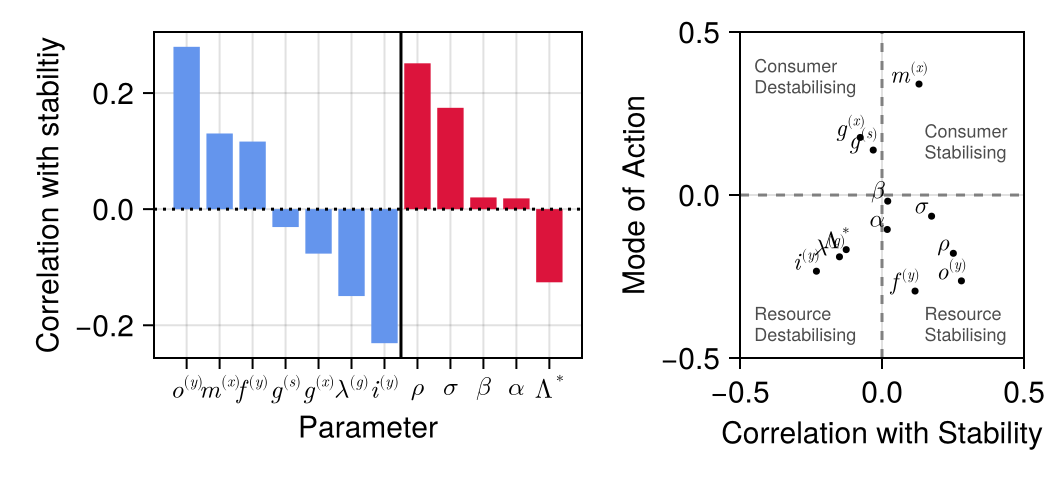

In [6]:
instab = .!stab

v = [norm(v[1:100])^2 for v = res["v"]]
con_cor = [cor(p[instab], v[instab]) for p = eachrow(p_mat)]

# #get color
c = vcat(fill(:cornflowerblue, length(fe_L)), fill(:crimson, length(fs_L)))
c = c[p_ind]

# # #sortnames
# ind = sortperm((stability_cor),rev=true)
ind = vcat(sortperm((stability_cor[1:7]),rev=true), 7 .+ sortperm((stability_cor[8:12]),rev=true))

f = Figure(size = (5.5inch, 2.5inch))
ax = Axis(f[1,1], xticks = (1:length(names_1), names_L_1[ind]),
    xlabel = "Parameter", ylabel = "Correlation with stabiltiy",
    xticklabelsize = 13, yticklabelsize = 15,
    xlabelsize = 15, ylabelsize = 15)

barplot!(ax, stability_cor[ind], color = c)
hlines!(ax, [0], linestyle = :dot, color = "black")
vlines!(ax, [7.5], color = :black)


ax = Axis(f[1,2], xlabel = "Correlation with Stability", ylabel = "Mode of Action", xticklabelsize = 15, yticklabelsize = 15,
    xlabelsize = 15, ylabelsize = 15)

hlines!(ax, [0], color = (:grey), linestyle = :dash)
vlines!(ax, [0], color = (:grey), linestyle = :dash)

consumer_index = -sign.(stability_cor) .* con_cor
plot!(ax, stability_cor, consumer_index, markersize = 5, color = :black)
text!(ax, stability_cor, consumer_index, text = names_L_1, offset = (-5,5), align = (0.5,0.5), fontsize = 12)

text!(ax, -0.45,0.3, text = "Consumer\nDestabilising", fontsize = 9, color = :grey30)
text!(ax, -0.45,-0.46, text = "Resource\nDestabilising", fontsize = 9, color = :grey30)
text!(ax, 0.15, 0.1, text = "Consumer\nStabilising", fontsize = 9, color = :grey30)
text!(ax, 0.15,-0.46, text = "Resource\nStabilising", fontsize = 9, color = :grey30)


xlims!(ax, (-0.5,0.5))
ylims!(ax, (-0.5,0.5))

colsize!(f.layout, 1, Relative(6/10))

f

In [7]:
save("../Results/Figures/stability_correlations.pdf", f)

CairoMakie.Screen{PDF}


# Size

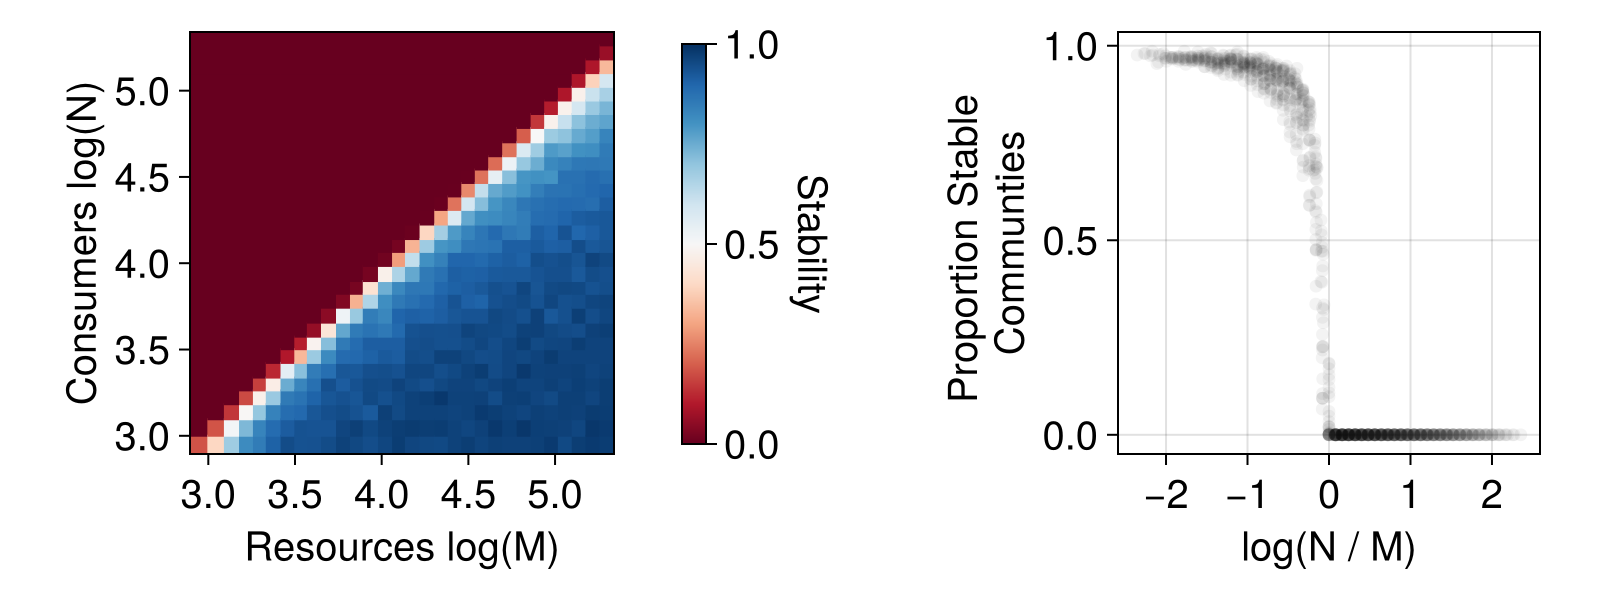

In [14]:
res = load("../Results/data/size_stability.jld2")
stab = [(x.re) .< -1e-6 for x = res["l"]]

#params
#params
N = 30
M = 30
Np = 500

n_vec = Int.(floor.(10 .^ range(log10(20), log10(200), length = N)))
m_vec = Int.(floor.(10 .^ range(log10(20), log10(200), length = M)))

#fix graphical errorr
n_vec[1] = 19
m_vec[1] = 19

N_mat = [n_vec[i] for i = 1:N, j = 1:M]
M_mat = [m_vec[j] for i = 1:N, j = 1:M]

stab = mean(stab,dims=3)[:,:,1]

f = Figure(size = (800,300))

#plot stabiltiy heatmap
ax = Axis(f[1,1], ylabel = "Consumers log(N)", xlabel = "Resources log(M)", aspect = 1, xticklabelsize = 20, yticklabelsize = 20, xlabelsize = 20, ylabelsize = 20)
cm = :RdBu

heatmap!(ax, log.(m_vec), log.(n_vec), (stab'), colormap = (cm), colorrange = (0,1))
Colorbar(f[1,2], colormap = (cm), label = "Stability", 
    flip_vertical_label = true, labelsize = 20, ticklabelsize = 20, tellheight = false, height = 200)

# cm = :RdBu

ax2 = Axis(f[1,3], aspect = 1, ylabel =  "Proportion Stable \nCommunties", xlabel = "log(N / M)", xticklabelsize = 20, yticklabelsize = 20, xlabelsize = 20, ylabelsize = 20)

scatter!(ax2, log.(N_mat[:] ./ M_mat[:]), stab[:] ,  colormap = (:Blues), color = (:black, 0.05))

colsize!(f.layout, 2, Relative(0.1))
# rowgap!(f.layout,1, Relative(0.1))
colgap!(f.layout,1 ,0.0)



f

In [15]:
save("../Results/Figures/size_correlations.pdf", f)

CairoMakie.Screen{PDF}


In [11]:
res = load("../Results/data/trophic_stability.jld2")

Dict{String, Any} with 3 entries:
  "Λ" => 0.5:0.125:1.0
  "σ" => 0.0:0.041666666666666664:1.0
  "l" => [-0.0260661 -0.00415271 … -0.0337577 -0.00636061; -0.0257691 -0.002037…

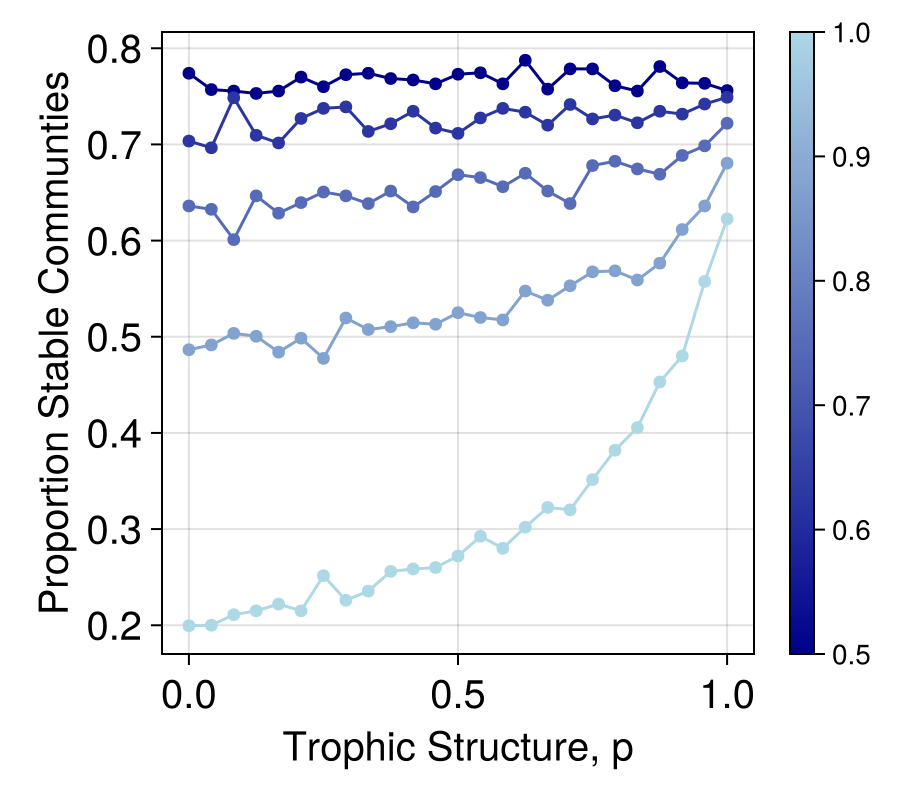

In [12]:
f = Figure(size = (450,400))
hidedecorations!(ax)

#stability result
Λ_vec = res["Λ"]
σ_vec = res["σ"]
stab_mat = mean(real.(res["l"]) .< 0, dims = 3)[:,:,1]

ax = Axis(f[1, 1], ylabel = "Proportion Stable Communties",xlabel = "Trophic Structure, p",xticklabelsize = 20, yticklabelsize = 20, xlabelsize = 20, ylabelsize = 20)
for i = eachindex(Λ_vec)
    scatter!(ax, 1 .- σ_vec, stab_mat[:,i], color = (Λ_vec)[i], colorrange = extrema(Λ_vec), colormap = Reverse(:blues))
    lines!(ax, 1 .- σ_vec, stab_mat[:,i], color = (Λ_vec)[i], colorrange = extrema(Λ_vec), colormap = Reverse(:blues))
end
# colgap!(f.layout, 1, Relative(0.10))
# colsize!(f.layout, 1, Relative(0.35))

Colorbar(f[1,2], colorrange = extrema(Λ_vec), colormap = Reverse(:blues))

f

In [13]:
save("../Results/Figures/trophic_stability.pdf", f)

CairoMakie.Screen{PDF}
